# Tutorials_rectification

In [1]:
import scanpy as sc
import torch
import os
import pandas as pd
import community as louvain
os.chdir("/public/home/off_liukunpeng/project/11_cluster_problem/AgaeSMO")
import AgaeSMO as AgaeSMO_v1
import numpy as np
import anndata as ad
from scipy.sparse import csr_matrix
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

In [2]:
def cons_ms_adata(ms_org,he_coordinate=False,image_path=False,in_tissue=False):
   # pd dataframe ms_org x|y|ms_1|ms_2|ms_3|...
   # pd dataframe he_coordinate he_x|he_y    with same range as ms_org

    ##select in tissue spot
    if in_tissue:
        in_tissue_bool=pd.Series(np.sum(np.array(ms_org.iloc[:,2:]),axis=1))!=0
        # remove zero spot
        ms_org=ms_org.loc[in_tissue_bool,:]
        he_coordinate=he_coordinate.loc[in_tissue_bool,:]
        print(ms_org.shape)
    
    #constructing obs assign spot name
    spot=[f"mspx_{i}" for i in range(len(ms_org))]

    ms_intensity = csr_matrix(ms_org.iloc[:,2:], dtype=np.float32)

    adata = ad.AnnData(ms_intensity)

    adata.var_names=ms_org.columns[2:] #m/z range
    adata.obs_names=spot #spot name
    
    #original coordinate
    adata.obs["array_row"]=list(ms_org.iloc[:,0])##raw x
    adata.obs["array_col"]=list(ms_org.iloc[:,1])##raw y

    if type(he_coordinate)==pd.core.frame.DataFrame:
        adata.obsm["spatial"]=he_coordinate.to_numpy()
    else:
        adata.obsm["spatial"]=ms_org.loc[:,["x","y"]].to_numpy()

    if image_path!=False:
        image = Image.open(image_path)
        image_array = np.array(image)
        spatial_key = "spatial"
        library_id = "tissue"
        adata.uns[spatial_key] = {library_id: {}}
        adata.uns[spatial_key][library_id]["images"] = {"hires": image_array}
        adata.uns[spatial_key][library_id]["scalefactors"] = {
            "tissue_hires_scalef": 1,
            "spot_diameterres_full": 1,
            'spot_diameter_fullres': 1
        }
    return adata

<font size="5"> Read data </font>

<font size="5"> Can be found at https://data.mendeley.com/datasets/w7nw4km7xd/1 </font>

In [14]:
ms_table=pd.read_csv("/public/home/off_liukunpeng/project/11_cluster_problem/data/sma/V11L12-109_A1/V11L12-109_A1_MSI/V11L12-109_A1.Visium.FMP.220826_smamsi.csv")
adata_omics1=sc.read_visium("/public/home/off_liukunpeng/project/11_cluster_problem/data/sma/V11L12-109_A1/V11L12-109_A1_RNA/")
image = Image.open("/public/home/off_liukunpeng/project/11_cluster_problem/data/sma/V11L12-109_A1/V11L12-109_A1_RNA/spatial/tissue_hires_image.png")



/public/home/off_liukunpeng/software/anaconda3/envs/pyg1/lib/python3.9/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/public/home/off_liukunpeng/software/anaconda3/envs/pyg1/lib/python3.9/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


<font size="5">  Construct adata from MSI Table </font>

In [4]:
adata_omics2=cons_ms_adata(ms_table,ms_table.iloc[:,[0,1]],image_path="/public/home/off_liukunpeng/project/11_cluster_problem/data/sma/V11L12-109_A1/V11L12-109_A1_RNA/spatial/tissue_hires_image.png",in_tissue=True)


(2438, 1540)


In [5]:
st_keys=list(adata_omics1.uns["spatial"].keys())[0]


/public/home/off_liukunpeng/software/anaconda3/envs/pyg1/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


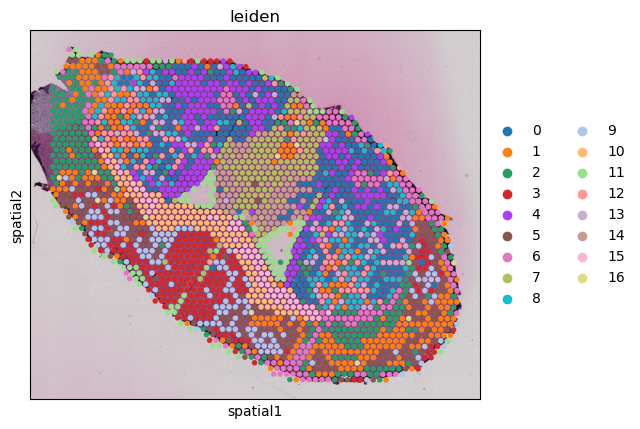

In [6]:
sc.pp.pca(adata_omics1)
sc.pp.neighbors(adata_omics1)
sc.tl.leiden(adata_omics1,resolution=1)
sc.pl.spatial(adata_omics1,spot_size=500,color="leiden")

/public/home/off_liukunpeng/software/anaconda3/envs/pyg1/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


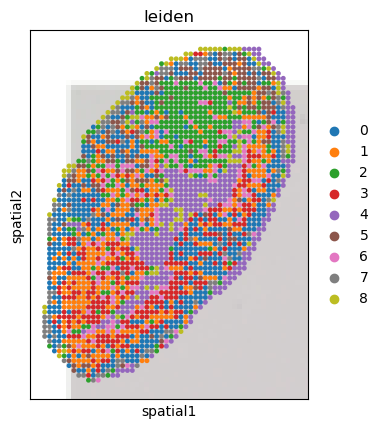

In [7]:
sc.pp.pca(adata_omics2)
sc.pp.neighbors(adata_omics2)
sc.tl.leiden(adata_omics2,resolution=0.5)
sc.pl.spatial(adata_omics2,spot_size=1,color="leiden")

In [8]:
org_coor=adata_omics2.obsm["spatial"]
adata_omics1.obsm["HE_domain_coor"]=adata_omics1.obsm["spatial"]*adata_omics1.uns["spatial"][st_keys]["scalefactors"]["tissue_hires_scalef"]


In [9]:
adata_omics1_leiden_color = adata_omics1.obs['leiden'].cat.codes if hasattr(adata_omics1.obs['leiden'], 'cat') \
               else adata_omics1.obs['leiden'].astype('category').cat.codes
adata_omics2_leiden_color = adata_omics2.obs['leiden'].cat.codes if hasattr(adata_omics2.obs['leiden'], 'cat') \
               else adata_omics2.obs['leiden'].astype('category').cat.codes

$$A =
\begin{bmatrix}
s\cos\theta & -s\sin\theta \\
s\sin\theta &  s\cos\theta
\end{bmatrix}$$
$$P' = A\,P + p,\qquad i = 1,\dots,N$$


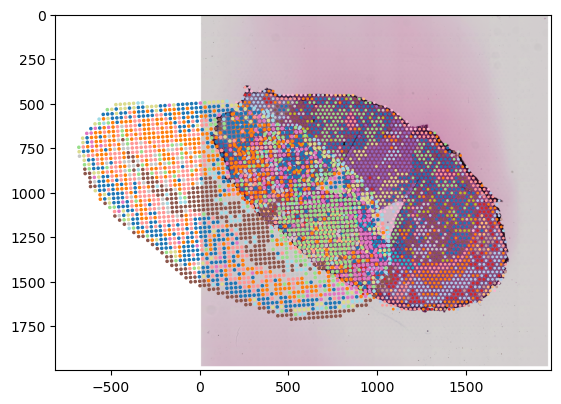

In [10]:
theta=1.5
s=25
A=np.array([[ s*np.cos(theta),  -s*np.sin(theta)],
        [s*np.sin(theta), s*np.cos(theta)]])
p=np.array([1000,  400])

adata_omics2.obsm["spatial"]=np.matmul(A,org_coor.T).T+p

plt.imshow(image)
plt.scatter(adata_omics1.obsm["HE_domain_coor"][:,0],adata_omics1.obsm["HE_domain_coor"][:,1],
            s=1,
            c=adata_omics1_leiden_color,
            cmap='tab20')
plt.scatter(adata_omics2.obsm["spatial"][:,0],adata_omics2.obsm["spatial"][:,1],
            s=s*0.1,
            c=adata_omics2_leiden_color,
            cmap='tab20')

<font size="5"> Adjust the affine transformation so that the MSI pixel coordinates reach approximately the correct position. <font>

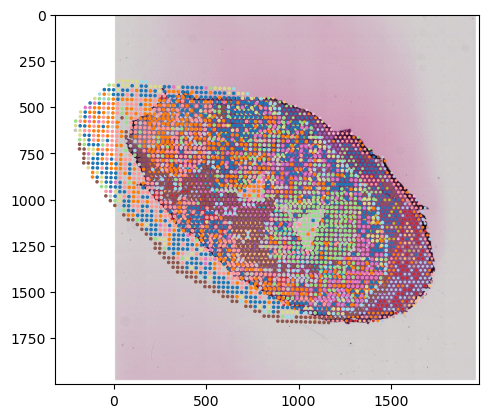

In [11]:
theta=1.6
s=25
A=np.array([[ s*np.cos(theta),  -s*np.sin(theta)],
        [s*np.sin(theta), s*np.cos(theta)]])
p=np.array([1500,  400])
adata_omics2.obsm["spatial"]=np.matmul(A,org_coor.T).T+p

plt.imshow(image)
plt.scatter(adata_omics1.obsm["HE_domain_coor"][:,0],adata_omics1.obsm["HE_domain_coor"][:,1],
            s=1,
            c=adata_omics1_leiden_color,
            cmap='tab20')
plt.scatter(adata_omics2.obsm["spatial"][:,0],adata_omics2.obsm["spatial"][:,1],
            s=s*0.1,
            c=adata_omics2_leiden_color,
            cmap='tab20')

##### Multiplying adata.obsm["spatial"] by scalefactors will yield the coordinates of the spots on the H&E image. 
##### AgaeSMO uses the coordinates on the H&E image to construct an unpaired modality adjacency graph; 
##### please store it in adata.obsm["HE_domain_coor"].

In [12]:

st_keys=list(adata_omics1.uns["spatial"].keys())[0]
adata_omics1.obsm["HE_domain_coor"]=adata_omics1.obsm["spatial"]*adata_omics1.uns["spatial"][st_keys]["scalefactors"]["tissue_hires_scalef"]
adata_omics2.obsm["HE_domain_coor"]=adata_omics2.obsm["spatial"]


In [13]:

# adata_omics1 = sc.write_h5ad("st.h5ad")
# adata_omics2 = sc.write_h5ad("ms.h5ad")

 <font size="5"> The h5ad file at https://zenodo.org/records/22934477 stores coordinates（adata.obsm["spatial"]） that have undergone affine transformation and can be used directly.<font>